In [ ]:

import pandas as pd
from google.colab import files
from io import BytesIO

# 1. Subir nuestro dataset
archivos = files.upload()

nombre = next(iter(archivos))
contenido = BytesIO(archivos[nombre])

# 2. Leer el archivo
if nombre.lower().endswith(".csv"):
    try:
        datos = pd.read_csv(contenido, sep=None, engine="python")
    except UnicodeDecodeError:
        contenido.seek(0)
        datos = pd.read_csv(
            contenido, sep=None, engine="python",
            encoding="latin-1"
        )
elif nombre.lower().endswith(".xlsx"):
    datos = pd.read_excel(contenido)
else:
    raise ValueError("Sube un archivo CSV o XLSX")

# 3. Conocer nuestra información
print("Número de registros:", len(datos))
print("Número de columnas:", len(datos.columns))

print("\nNombres de las columnas:")
print(datos.columns.tolist())

print("\nPrimeros registros:")
display(datos.head())

print("\nValores faltantes por columna:")
display(datos.isnull().sum())

Saving VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261111.csv to VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261111.csv
Número de registros: 450335
Número de columnas: 9

Nombres de las columnas:
['MARCA_VEHICULO', 'MODELO_VEHICULO', 'TIPO_VEHICULO', 'EDAD_VEHICULO', 'FECHA_ACCIDENTE', 'GRAVEDAD_ACCIDENTE', 'DEPARTAMENTO_ACCIDENTE', 'MUNICIPIO_ACCIDENTE', 'AUTORIDAD_DE_TRANSITO']

Primeros registros:


,MARCA_VEHICULO,MODELO_VEHICULO,TIPO_VEHICULO,EDAD_VEHICULO,FECHA_ACCIDENTE,GRAVEDAD_ACCIDENTE,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,AUTORIDAD_DE_TRANSITO
0,VOLKSWAGEN,2018,CAMION,7,09/2026,CON HERIDOS,ANTIOQUIA,MEDELLIN,DIRECCION DE TRANSITO Y TRANSPORTE
1,AKT,2024,MOTOCICLETA,3,09/2026,CON HERIDOS,ANTIOQUIA,MEDELLIN,DIRECCION DE TRANSITO Y TRANSPORTE
2,YAMAHA,2022,MOTOCICLETA,5,09/2026,CON HERIDOS,ANTIOQUIA,GIRARDOTA,DIRECCION DE TRANSITO Y TRANSPORTE
3,FOTON,2022,TRACTOCAMION,5,09/2026,CON HERIDOS,ANTIOQUIA,GIRARDOTA,DIRECCION DE TRANSITO Y TRANSPORTE
4,YAMAHA,2023,MOTOCICLETA,4,09/2026,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOyTTE BUCARAMANGA



Valores faltantes por columna:


,0
MARCA_VEHICULO,0
MODELO_VEHICULO,0
TIPO_VEHICULO,0
EDAD_VEHICULO,20
FECHA_ACCIDENTE,0
GRAVEDAD_ACCIDENTE,0
DEPARTAMENTO_ACCIDENTE,0
MUNICIPIO_ACCIDENTE,0
AUTORIDAD_DE_TRANSITO,0


In [ ]:

# Crear una copia del dataset original
df = datos.copy()

# Normalizar el nombre del departamento
df["DEPARTAMENTO_ACCIDENTE"] = (
    df["DEPARTAMENTO_ACCIDENTE"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Filtrar registros de Boyacá
boyaca = df[
    df["DEPARTAMENTO_ACCIDENTE"] == "BOYACA"
].copy()

# Convertir fechas
boyaca["FECHA_ACCIDENTE"] = pd.to_datetime(
    boyaca["FECHA_ACCIDENTE"],
    errors="coerce"
)

# Mostrar resultados
print("REGISTROS DE BOYACÁ:", len(boyaca))

print("\nREGISTROS POR MUNICIPIO:")
print(
    boyaca["MUNICIPIO_ACCIDENTE"]
    .value_counts()
    .head(20)
)

print("\nREGISTROS POR AÑO:")
print(
    boyaca["FECHA_ACCIDENTE"]
    .dt.year
    .value_counts()
    .sort_index()
)

print("\nCATEGORÍAS DE GRAVEDAD:")
print(
    boyaca["GRAVEDAD_ACCIDENTE"]
    .value_counts()
)

print("\nPRIMEROS REGISTROS:")
display(boyaca.head())


REGISTROS DE BOYACÁ: 5277

REGISTROS POR MUNICIPIO:
MUNICIPIO_ACCIDENTE
TUNJA                    1621
DUITAMA                   595
COMBITA                   454
CHIQUINQUIRA              375
NOBSA                     298
VILLA DE LEYVA            285
PAIPA                     268
MONIQUIRA                 267
PUERTO BOYACA             239
SOGAMOSO                  212
SANTA ROSA DE VITERBO     166
GUATEQUE                  165
SABOYA                     97
GARAGOA                    91
BELEN                      43
SOATA                      35
CÓMBITA - EL BARNE          9
TIBASOSA                    8
SAMACA                      7
SANTANA                     5
Name: count, dtype: int64

REGISTROS POR AÑO:
FECHA_ACCIDENTE
2022    1256
2023    1034
2024    1052
2025    1112
2026     823
Name: count, dtype: int64

CATEGORÍAS DE GRAVEDAD:
GRAVEDAD_ACCIDENTE
CON HERIDOS    4651
CON MUERTOS     626
Name: count, dtype: int64

PRIMEROS REGISTROS:


/tmp/ipykernel_452/3936052196.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  boyaca["FECHA_ACCIDENTE"] = pd.to_datetime(


,MARCA_VEHICULO,MODELO_VEHICULO,TIPO_VEHICULO,EDAD_VEHICULO,FECHA_ACCIDENTE,GRAVEDAD_ACCIDENTE,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,AUTORIDAD_DE_TRANSITO
47,CHEVROLET,2008,CAMION,19,2026-08-01,CON HERIDOS,BOYACA,SOGAMOSO,DIRECCION DE TRANSITO Y TRANSPORTE
48,AUTECO,2007,MOTOCICLETA,20,2026-08-01,CON HERIDOS,BOYACA,SOGAMOSO,DIRECCION DE TRANSITO Y TRANSPORTE
51,QINGQI,2011,MOTOCICLETA,15,2026-08-01,CON HERIDOS,BOYACA,NOBSA,DIRECCION DE TRANSITO Y TRANSPORTE
303,TVS,2014,MOTOCICLETA,13,2026-08-01,CON HERIDOS,BOYACA,NOBSA,DIRECCION DE TRANSITO Y TRANSPORTE
380,BAJAJ,2017,MOTOCICLETA,9,2026-08-01,CON HERIDOS,BOYACA,CHIQUINQUIRA,STRIA MCPAL TTOyTTE CHIQUINQUIRÁ


In [ ]:

# PASO 3 - Preparar nuestra zona de estudio

import pandas as pd

# Copiamos la información de Boyacá
df = boyaca.copy()

# Normalizamos los nombres de municipios
df["MUNICIPIO_ACCIDENTE"] = (
    df["MUNICIPIO_ACCIDENTE"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Extraer año y mes
df["ANIO"] = df["FECHA_ACCIDENTE"].dt.year
df["MES"] = df["FECHA_ACCIDENTE"].dt.month

# Filtrar años completos
df = df[df["ANIO"].between(2022, 2025)].copy()

# Municipios principales del proyecto
municipios = ["TUNJA", "DUITAMA", "SOGAMOSO"]

df_zona = df[
    df["MUNICIPIO_ACCIDENTE"].isin(municipios)
].copy()

print("REGISTROS TOTALES 2022-2025:", len(df))
print("REGISTROS DE LA ZONA:", len(df_zona))

# Registros por municipio y año
tabla = pd.crosstab(
    df_zona["MUNICIPIO_ACCIDENTE"],
    df_zona["ANIO"]
)

print("\nREGISTROS POR MUNICIPIO Y AÑO:")
display(tabla)

# Registros por tipo de vehículo
print("\nTIPOS DE VEHÍCULOS:")
display(df_zona["TIPO_VEHICULO"].value_counts())

# Registros por gravedad
print("\nGRAVEDAD:")
display(df_zona["GRAVEDAD_ACCIDENTE"].value_counts())

# Comprobar la precisión de las fechas
print("\nDÍAS DEL MES REGISTRADOS:")
display(
    boyaca["FECHA_ACCIDENTE"]
    .dt.day
    .value_counts()
    .sort_index()
)

# Guardar un archivo filtrado para trabajar después
df_zona.to_csv(
    "accidentes_zona_estudio.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivo de estudio creado correctamente.")


REGISTROS TOTALES 2022-2025: 4454
REGISTROS DE LA ZONA: 2066

REGISTROS POR MUNICIPIO Y AÑO:


ANIO,2022,2023,2024,2025
MUNICIPIO_ACCIDENTE,,,,
DUITAMA,136,88,107,143
SOGAMOSO,48,42,72,35
TUNJA,386,302,323,384



TIPOS DE VEHÍCULOS:


,count
TIPO_VEHICULO,
MOTOCICLETA,871
AUTOMOVIL,581
CAMIONETA,261
CAMION,96
MICROBUS,90
CAMPERO,73
TRACTOCAMION,48
BUSETA,22
VOLQUETA,13



GRAVEDAD:


,count
GRAVEDAD_ACCIDENTE,
CON HERIDOS,1892
CON MUERTOS,174



DÍAS DEL MES REGISTRADOS:


,count
FECHA_ACCIDENTE,
1,5277



Archivo de estudio creado correctamente.


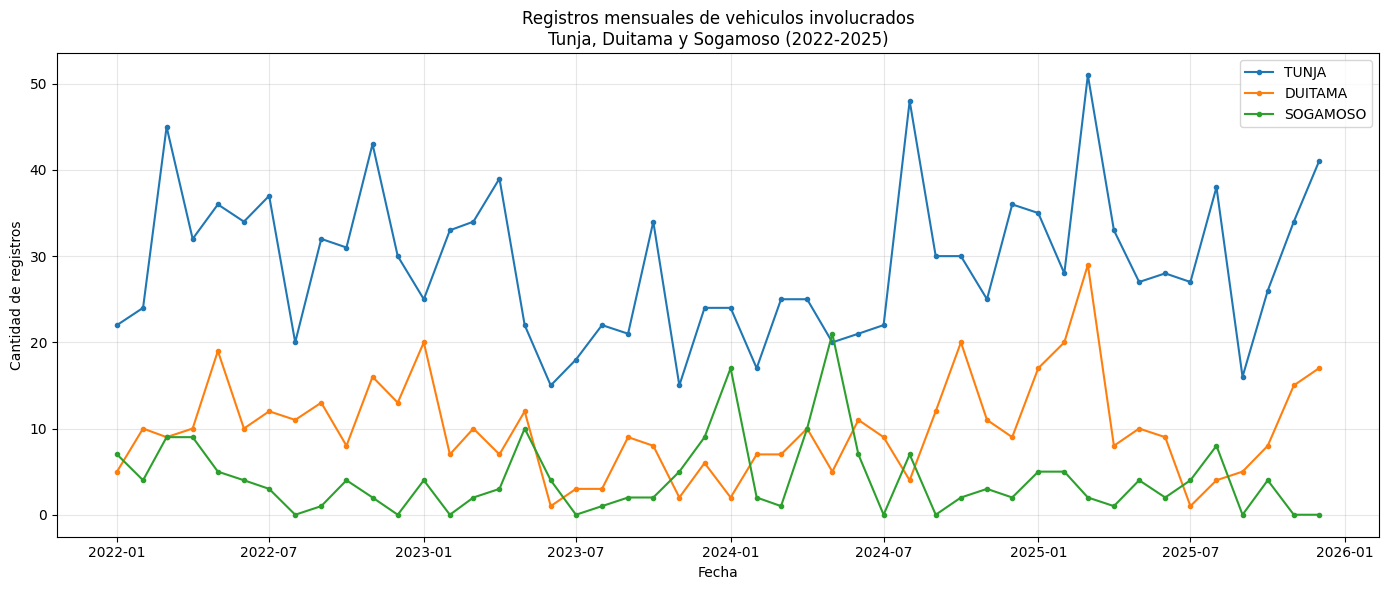

,MUNICIPIO_ACCIDENTE,FECHA_ACCIDENTE,REGISTROS
0,TUNJA,2022-01-01,22
1,TUNJA,2022-02-01,24
2,TUNJA,2022-03-01,45
3,TUNJA,2022-04-01,32
4,TUNJA,2022-05-01,36
5,TUNJA,2022-06-01,34
6,TUNJA,2022-07-01,37
7,TUNJA,2022-08-01,20
8,TUNJA,2022-09-01,32
9,TUNJA,2022-10-01,31


In [ ]:

# PASO 4 - Analisis mensual de accidentalidad

import pandas as pd
import matplotlib.pyplot as plt

# Crear los 48 meses del estudio
meses = pd.date_range(
    start="2022-01-01",
    end="2025-12-01",
    freq="MS"
)

# Contar registros mensuales por municipio
mensual = (
    df_zona.groupby([
        "MUNICIPIO_ACCIDENTE",
        pd.Grouper(key="FECHA_ACCIDENTE", freq="MS")
    ])
    .size()
    .rename("REGISTROS")
)

# Incluir meses sin registros en el dataset
indice = pd.MultiIndex.from_product(
    [municipios, meses],
    names=["MUNICIPIO_ACCIDENTE", "FECHA_ACCIDENTE"]
)

mensual = (
    mensual.reindex(indice, fill_value=0)
    .reset_index()
)

# Crear grafico
plt.figure(figsize=(14, 6))

for municipio in municipios:
    registros = mensual[
        mensual["MUNICIPIO_ACCIDENTE"] == municipio
    ]

    plt.plot(
        registros["FECHA_ACCIDENTE"],
        registros["REGISTROS"],
        marker="o",
        markersize=3,
        label=municipio
    )

plt.title(
    "Registros mensuales de vehiculos involucrados\n"
    "Tunja, Duitama y Sogamoso (2022-2025)"
)
plt.xlabel("Fecha")
plt.ylabel("Cantidad de registros")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Mostrar la tabla mensual
display(mensual.head(15))

# Guardar datos mensuales
mensual.to_csv(
    "registros_mensuales_boyaca.csv",
    index=False
)


In [ ]:

# PASO 5 - Primer entrenamiento de Machine Learning

import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# 1. Partimos de nuestros registros mensuales
modelo_df = mensual.copy()

modelo_df = modelo_df.sort_values(
    ["MUNICIPIO_ACCIDENTE", "FECHA_ACCIDENTE"]
)

# 2. Crear variables de entrada
modelo_df["MES"] = modelo_df["FECHA_ACCIDENTE"].dt.month

# Cantidad de registros del mes anterior
modelo_df["MES_ANTERIOR"] = (
    modelo_df.groupby("MUNICIPIO_ACCIDENTE")["REGISTROS"]
    .shift(1)
)

# Promedio de los tres meses anteriores
modelo_df["PROMEDIO_3_MESES"] = (
    modelo_df.groupby("MUNICIPIO_ACCIDENTE")["REGISTROS"]
    .transform(lambda s: s.shift(1).rolling(3).mean())
)

# Eliminar filas sin historial suficiente
modelo_df = modelo_df.dropna().copy()

# 3. Convertir municipio a variables numericas
columnas = [
    "MUNICIPIO_ACCIDENTE",
    "MES",
    "MES_ANTERIOR",
    "PROMEDIO_3_MESES"
]

X = pd.get_dummies(
    modelo_df[columnas],
    columns=["MUNICIPIO_ACCIDENTE"],
    dtype=int
)

# Variable que queremos estimar
y = modelo_df["REGISTROS"]

# 4. Separar datos por fecha
entrenamiento = modelo_df["FECHA_ACCIDENTE"] < "2025-01-01"
prueba = modelo_df["FECHA_ACCIDENTE"] >= "2025-01-01"

X_train = X.loc[entrenamiento]
X_test = X.loc[prueba]

y_train = y.loc[entrenamiento]
y_test = y.loc[prueba]

print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

# 5. Entrenar arbol de decision
arbol = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

arbol.fit(X_train, y_train)

# 6. Entrenar Random Forest
bosque = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

bosque.fit(X_train, y_train)

# 7. Obtener predicciones de 2025
pred_arbol = arbol.predict(X_test)
pred_bosque = bosque.predict(X_test)

# Referencia sencilla: usar el valor del mes anterior
pred_referencia = X_test["MES_ANTERIOR"]

# 8. Evaluar resultados
print("\nERROR ABSOLUTO MEDIO (MAE)")

print("Referencia:",
      round(mean_absolute_error(y_test, pred_referencia), 2))

print("Arbol de decision:",
      round(mean_absolute_error(y_test, pred_arbol), 2))

print("Random Forest:",
      round(mean_absolute_error(y_test, pred_bosque), 2))

# 9. Comparar valores reales y estimados
resultados = modelo_df.loc[
    prueba, ["FECHA_ACCIDENTE", "MUNICIPIO_ACCIDENTE", "REGISTROS"]
].copy()

resultados["PREDICCION_ARBOL"] = pred_arbol.round(1)
resultados["PREDICCION_RANDOM_FOREST"] = pred_bosque.round(1)

print("\nCOMPARACION DE RESULTADOS:")
display(resultados.head(15))


Datos de entrenamiento: 99
Datos de prueba: 36

ERROR ABSOLUTO MEDIO (MAE)
Referencia: 6.03
Arbol de decision: 6.61
Random Forest: 5.34

COMPARACION DE RESULTADOS:


,FECHA_ACCIDENTE,MUNICIPIO_ACCIDENTE,REGISTROS,PREDICCION_ARBOL,PREDICCION_RANDOM_FOREST
84,2025-01-01,DUITAMA,17,12.6,10.9
85,2025-02-01,DUITAMA,20,7.4,10.8
86,2025-03-01,DUITAMA,29,7.4,10.8
87,2025-04-01,DUITAMA,8,21.1,17.9
88,2025-05-01,DUITAMA,10,27.8,16.6
89,2025-06-01,DUITAMA,9,9.3,10.4
90,2025-07-01,DUITAMA,1,9.3,8.4
91,2025-08-01,DUITAMA,4,5.6,5.3
92,2025-09-01,DUITAMA,5,9.1,4.7
93,2025-10-01,DUITAMA,8,9.1,5.7


RENDIMIENTO POR MUNICIPIO:


,MAE_Referencia,MAE_Arbol,MAE_RandomForest,Promedio_Real
MUNICIPIO_ACCIDENTE,,,,
DUITAMA,5.67,8.19,6.47,11.92
SOGAMOSO,2.83,2.69,2.38,2.92
TUNJA,9.58,8.92,7.18,32.00


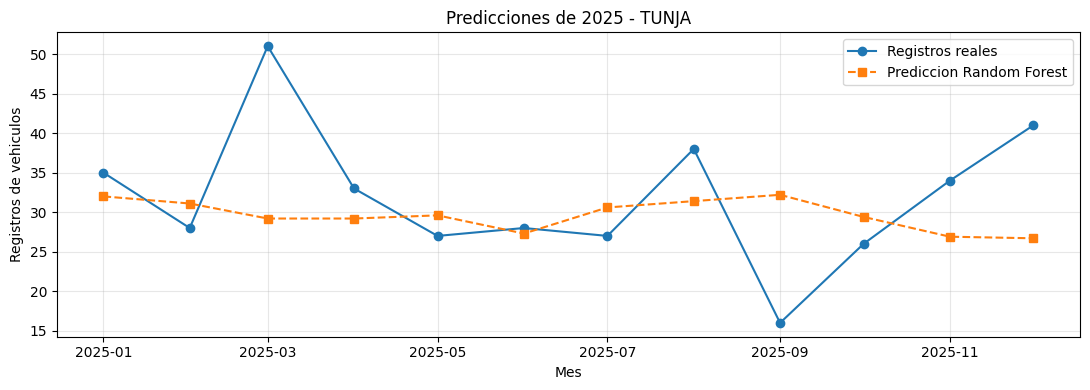

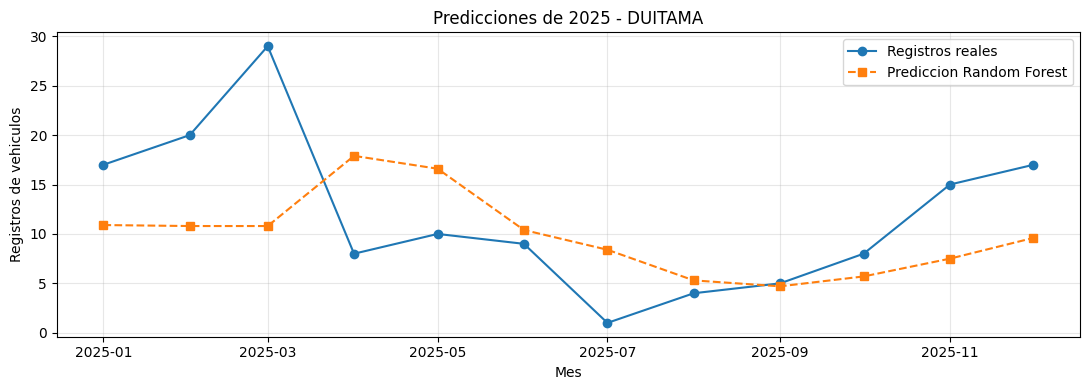

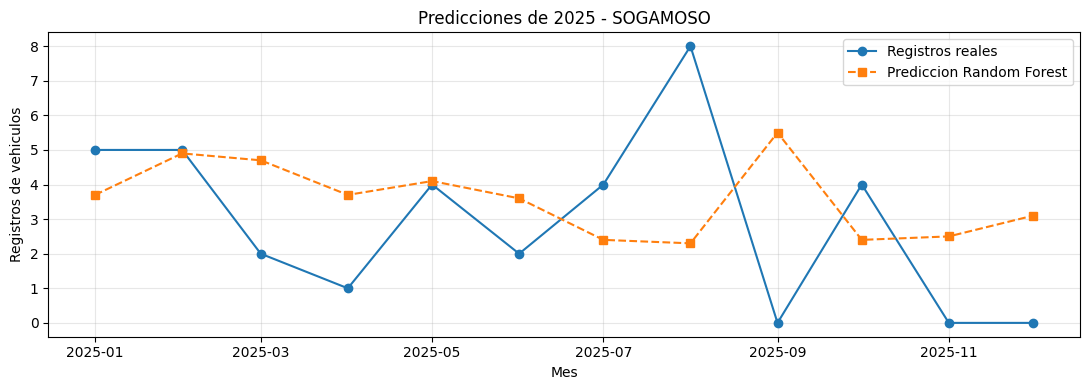

MAYORES ERRORES DEL MODELO:


,MUNICIPIO_ACCIDENTE,FECHA_ACCIDENTE,REGISTROS,PREDICCION_RANDOM_FOREST,ERROR_RF
38,TUNJA,2025-03-01,51,29.2,21.8
86,DUITAMA,2025-03-01,29,10.8,18.2
44,TUNJA,2025-09-01,16,32.2,16.2
47,TUNJA,2025-12-01,41,26.7,14.3
87,DUITAMA,2025-04-01,8,17.9,9.9
85,DUITAMA,2025-02-01,20,10.8,9.2
94,DUITAMA,2025-11-01,15,7.5,7.5
90,DUITAMA,2025-07-01,1,8.4,7.4
95,DUITAMA,2025-12-01,17,9.6,7.4
46,TUNJA,2025-11-01,34,26.9,7.1


In [ ]:

# PASO 6 - Evaluacion por municipio

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# Recuperar la referencia de cada prediccion
resultados["REFERENCIA"] = (
    modelo_df.loc[prueba, "MES_ANTERIOR"].to_numpy()
)

# Calcular errores absolutos
resultados["ERROR_RF"] = abs(
    resultados["REGISTROS"] -
    resultados["PREDICCION_RANDOM_FOREST"]
)

resultados["ERROR_ARBOL"] = abs(
    resultados["REGISTROS"] -
    resultados["PREDICCION_ARBOL"]
)

resultados["ERROR_REFERENCIA"] = abs(
    resultados["REGISTROS"] -
    resultados["REFERENCIA"]
)

# Comparar errores por municipio
evaluacion = resultados.groupby(
    "MUNICIPIO_ACCIDENTE"
).agg(
    MAE_Referencia=("ERROR_REFERENCIA", "mean"),
    MAE_Arbol=("ERROR_ARBOL", "mean"),
    MAE_RandomForest=("ERROR_RF", "mean"),
    Promedio_Real=("REGISTROS", "mean")
).round(2)

print("RENDIMIENTO POR MUNICIPIO:")
display(evaluacion)

# Visualizar predicciones por municipio
for municipio in ["TUNJA", "DUITAMA", "SOGAMOSO"]:

    datos_municipio = resultados[
        resultados["MUNICIPIO_ACCIDENTE"] == municipio
    ].sort_values("FECHA_ACCIDENTE")

    plt.figure(figsize=(11, 4))

    plt.plot(
        datos_municipio["FECHA_ACCIDENTE"],
        datos_municipio["REGISTROS"],
        marker="o",
        label="Registros reales"
    )

    plt.plot(
        datos_municipio["FECHA_ACCIDENTE"],
        datos_municipio["PREDICCION_RANDOM_FOREST"],
        marker="s",
        linestyle="--",
        label="Prediccion Random Forest"
    )

    plt.title(f"Predicciones de 2025 - {municipio}")
    plt.xlabel("Mes")
    plt.ylabel("Registros de vehiculos")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Mostrar los meses con mayores errores
print("MAYORES ERRORES DEL MODELO:")
display(
    resultados.nlargest(10, "ERROR_RF")[
        [
            "MUNICIPIO_ACCIDENTE",
            "FECHA_ACCIDENTE",
            "REGISTROS",
            "PREDICCION_RANDOM_FOREST",
            "ERROR_RF"
        ]
    ]
)


In [ ]:

# PASO 7 - Consultar accidentes georreferenciados

import requests
import pandas as pd

url = (
    "https://srvansvargweb.ansv.gov.co/server/rest/"
    "services/Hosted/Datos_siniestros/FeatureServer/0/query"
)

parametros = {
    "where": "depto_hech LIKE '%BOYAC%'",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": 4326,
    "resultRecordCount": 500,
    "f": "json"
}

respuesta = requests.get(
    url,
    params=parametros,
    timeout=45
)

respuesta.raise_for_status()
contenido = respuesta.json()

if "error" in contenido:
    raise Exception(contenido["error"])

registros = []

for elemento in contenido.get("features", []):
    fila = elemento["attributes"].copy()
    geometria = elemento.get("geometry") or {}

    # Usar coordenadas de la geometria cuando existan
    fila["LONGITUD_MAPA"] = geometria.get("x")
    fila["LATITUD_MAPA"] = geometria.get("y")

    registros.append(fila)

geo = pd.DataFrame(registros)

print("REGISTROS DE LA MUESTRA:", len(geo))

if not geo.empty:

    print("\nCOLUMNAS DISPONIBLES:")
    print(geo.columns.tolist())

    geo["FECHA"] = pd.to_datetime(
        geo["fecha_hech"],
        unit="ms",
        errors="coerce",
        utc=True
    )

    print("\nREGISTROS POR AÑO:")
    display(
        geo["FECHA"].dt.year
        .value_counts()
        .sort_index()
    )

    print("\nREGISTROS POR MUNICIPIO:")
    display(
        geo["municipio_"]
        .value_counts()
        .head(20)
    )

    print("\nCOORDENADAS FALTANTES:")
    print(
        geo[["LATITUD_MAPA", "LONGITUD_MAPA"]]
        .isna().sum()
    )

    print("\nPRIMEROS REGISTROS:")
    display(geo.head())
else:
    print("La consulta no devolvio registros.")


REGISTROS DE LA MUESTRA: 500

COLUMNAS DISPONIBLES:
['fid', 'hechos_id', 'latitud', 'mes_largo', 'sievi_clas', 'hipotesis_', 'medio_cono', 'smuertos', 'depto_hech', 'lugaro', 'tvictimas', 'longitud', 'fecha_hech', 'municipio_', 'slesionado', 'cid', 'LONGITUD_MAPA', 'LATITUD_MAPA']

REGISTROS POR AÑO:


,count
FECHA,
2019,500



REGISTROS POR MUNICIPIO:


,count
municipio_,
TUNJA (CT),141
DUITAMA,44
VENTAQUEMADA,25
SOGAMOSO,23
TIBASOSA,18
CHIQUINQUIRÁ,14
PAIPA,13
NOBSA,12
CÓMBITA,12



COORDENADAS FALTANTES:
LATITUD_MAPA     0
LONGITUD_MAPA    0
dtype: int64

PRIMEROS REGISTROS:


,fid,hechos_id,latitud,mes_largo,sievi_clas,hipotesis_,medio_cono,smuertos,depto_hech,lugaro,tvictimas,longitud,fecha_hech,municipio_,slesionado,cid,LONGITUD_MAPA,LATITUD_MAPA,FECHA
0,2,23948511,5.865535,Enero,CHOQUE,SALIRSE DE LA CALZADA,POLICIA DE TRANSITO RURAL,0,BOYACÁ,Vias Rurales,1,-73.004564,1546300800000,SANTA ROSA DE VITERBO,1,2,-73.004564,5.865535,2019-01-01 00:00:00+00:00
1,20,23949466,6.491814,Enero,VOLCAMIENTO,EMBRIAGUEZ APARENTE,POR INFORMACION POLICIVA,2,BOYACÁ,Vias Rurales,4,-72.508572,1546300800000,EL ESPINO,2,20,-72.508572,6.491814,2019-01-01 00:00:00+00:00
2,24,23949543,5.658914,Enero,CHOQUE,NO MANTENER DISTANCIA DE SEGURIDAD,POLICIA DE TRANSITO RURAL,0,BOYACÁ,Via Nacional,1,-73.785882,1546300800000,SABOYÁ,1,24,-73.785882,5.658914,2019-01-01 00:00:00+00:00
3,63,23953520,6.152410,Enero,VOLCAMIENTO,"FALTA DE PRECAUCIÓN POR NIEBLA, LLUVIA O HUMO",POR INFORMACION POLICIVA,1,BOYACÁ,Vias Rurales,2,-72.701334,1546387200000,SATIVANORTE,1,63,-72.701334,6.152410,2019-01-02 00:00:00+00:00
4,75,23954178,5.525375,Enero,CHOQUE,EMBRIAGUEZ O SUSTANCIAS ALUCINOGENAS\n,POR INFORMACION POLICIVA,0,BOYACÁ,Via urbana,2,-73.355360,1546300800000,TUNJA (CT),2,75,-73.355360,5.525375,2019-01-01 00:00:00+00:00


In [ ]:

# PASO 8 - Verificar cobertura temporal de la ANSV

import requests
import pandas as pd

url = (
    "https://srvansvargweb.ansv.gov.co/server/rest/"
    "services/Hosted/Datos_siniestros/FeatureServer/0/query"
)

def contar_registros(filtro):
    parametros = {
        "where": filtro,
        "returnCountOnly": "true",
        "f": "json"
    }

    respuesta = requests.get(
        url, params=parametros, timeout=45
    )
    respuesta.raise_for_status()
    resultado = respuesta.json()

    if "error" in resultado:
        raise ValueError(resultado["error"])

    return resultado["count"]


# 1. Contar todos los registros de Boyaca
filtro_boyaca = "depto_hech LIKE '%BOYAC%'"

total = contar_registros(filtro_boyaca)

print("TOTAL DE REGISTROS EN BOYACÁ:", total)

# 2. Consultar cuantos registros existen por año
conteos = []

for anio in range(2019, 2027):

    filtro = (
        f"{filtro_boyaca} "
        f"AND fecha_hech >= DATE '{anio}-01-01' "
        f"AND fecha_hech < DATE '{anio + 1}-01-01'"
    )

    cantidad = contar_registros(filtro)

    conteos.append({
        "AÑO": anio,
        "REGISTROS": cantidad
    })

# 3. Mostrar resultados
tabla_anios = pd.DataFrame(conteos)

print("\nCOBERTURA TEMPORAL:")
display(tabla_anios)

# 4. Comprobar nuestro periodo de estudio
periodo = tabla_anios[
    tabla_anios["AÑO"].between(2022, 2025)
]

print(
    "\nREGISTROS DISPONIBLES 2022-2025:",
    periodo["REGISTROS"].sum()
)


TOTAL DE REGISTROS EN BOYACÁ: 547

COBERTURA TEMPORAL:


,AÑO,REGISTROS
0,2019,547
1,2020,0
2,2021,0
3,2022,0
4,2023,0
5,2024,0
6,2025,0
7,2026,0



REGISTROS DISPONIBLES 2022-2025: 0


In [ ]:

# PASO 9 - Buscar datos geograficos recientes

import requests
import pandas as pd

url = (
    "https://srvansvargweb.ansv.gov.co/server/rest/"
    "services/Hosted/Fallecidos_2023_2024/"
    "FeatureServer/1/query"
)

def contar(filtro):
    parametros = {
        "where": filtro,
        "returnCountOnly": "true",
        "f": "json"
    }

    respuesta = requests.get(
        url,
        params=parametros,
        timeout=45
    )

    respuesta.raise_for_status()
    datos_api = respuesta.json()

    if "error" in datos_api:
        raise ValueError(datos_api["error"])

    return datos_api["count"]


# Filtrar registros del departamento de Boyaca
filtro = "departamento_ubicacion LIKE '%BOYAC%'"

print("TOTAL BOYACA:", contar(filtro))

# Consultar los años disponibles
resultados_anios = []

for anio in range(2022, 2026):

    consulta = (
        f"{filtro} "
        f"AND fechahecho >= DATE '{anio}-01-01' "
        f"AND fechahecho < DATE '{anio+1}-01-01'"
    )

    cantidad = contar(consulta)

    resultados_anios.append({
        "ANIO": anio,
        "REGISTROS": cantidad
    })

tabla = pd.DataFrame(resultados_anios)

print("\nREGISTROS GEOGRAFICOS POR AÑO:")
display(tabla)


TOTAL BOYACA: 168

REGISTROS GEOGRAFICOS POR AÑO:


,ANIO,REGISTROS
0,2022,0
1,2023,100
2,2024,68
3,2025,0


In [ ]:

import folium
from folium.plugins import MarkerCluster, HeatMap
from getpass import getpass

# Solicitar clave sin mostrarla en el notebook
api_key = getpass("Introduce tu API Key de CARTO: ")

# Crear mapa
mapa = folium.Map(
    location=[5.69, -73.12],
    zoom_start=10,
    tiles=None
)

# Añadir proveedor CARTO con API Key
folium.TileLayer(
    tiles=(
        "https://basemaps.cartocdn.com/rastertiles/"
        "light_all/{z}/{x}/{y}.png?key=" + api_key
    ),
    attr="© OpenStreetMap contributors, © CARTO",
    name="Mapa de carreteras",
    max_zoom=20
).add_to(mapa)

# Añadir los registros geográficos
puntos_validos = df_cercanos.dropna(
    subset=["LATITUD", "LONGITUD"]
).copy()

marcadores = MarkerCluster(
    name="Registros geográficos"
).add_to(mapa)

for _, fila in puntos_validos.iterrows():
    folium.CircleMarker(
        location=[fila["LATITUD"], fila["LONGITUD"]],
        radius=5,
        color="red",
        fill=True,
        fill_opacity=0.8,
        tooltip=str(fila["municipio_ubicacion"])
    ).add_to(marcadores)

# Añadir mapa de calor
if not puntos_validos.empty:
    calor = folium.FeatureGroup(
        name="Mapa de calor",
        show=False
    )

    HeatMap(
        puntos_validos[["LATITUD", "LONGITUD"]].values.tolist(),
        radius=18
    ).add_to(calor)

    calor.add_to(mapa)

    # Ajustar el mapa a la ubicación de los puntos
    mapa.fit_bounds([
        [
            puntos_validos["LATITUD"].min(),
            puntos_validos["LONGITUD"].min()
        ],
        [
            puntos_validos["LATITUD"].max(),
            puntos_validos["LONGITUD"].max()
        ]
    ])

folium.LayerControl().add_to(mapa)
display(mapa)


Introduce tu API Key de CARTO: ··········


In [ ]:

# PASO 11 - Revisar la calidad de las coordenadas

import pandas as pd

# Utilizar los registros del mapa
revision = df_cercanos.copy()

# Redondear coordenadas para comparar ubicaciones
revision["LAT_RED"] = revision["LATITUD"].round(5)
revision["LON_RED"] = revision["LONGITUD"].round(5)

# Contar coordenadas diferentes
ubicaciones = revision.groupby(
    ["LAT_RED", "LON_RED"]
).size().reset_index(name="REGISTROS")

ubicaciones = ubicaciones.sort_values(
    "REGISTROS",
    ascending=False
)

print("TOTAL DE REGISTROS:", len(revision))

print(
    "UBICACIONES DIFERENTES:",
    len(ubicaciones)
)

print(
    "UBICACIONES CON VARIOS REGISTROS:",
    (ubicaciones["REGISTROS"] > 1).sum()
)

print("\nUBICACIONES MAS REPETIDAS:")
display(ubicaciones.head(15))

print("\nREGISTROS POR MUNICIPIO:")
display(
    revision["municipio_ubicacion"]
    .value_counts()
)

print("\nCOLUMNAS DISPONIBLES:")
print(revision.columns.tolist())


TOTAL DE REGISTROS: 65
UBICACIONES DIFERENTES: 60
UBICACIONES CON VARIOS REGISTROS: 5

UBICACIONES MAS REPETIDAS:


,LAT_RED,LON_RED,REGISTROS
16,5.56370,-73.33854,2
19,5.65715,-72.92929,2
59,5.86350,-73.03133,2
51,5.81621,-73.07224,2
45,5.80631,-73.03079,2
4,5.52635,-73.36633,1
6,5.53664,-73.35723,1
7,5.54150,-73.35642,1
8,5.55459,-73.35121,1
5,5.52941,-73.36078,1



REGISTROS POR MUNICIPIO:


,count
municipio_ubicacion,
Duitama,20
Tunja,19
Sogamoso,17
Tibasosa,3
Nobsa,2
Cómbita,2
Paipa,2



COLUMNAS DISPONIBLES:
['departamento_ubicacion', 'circunstancia', 'edad', 'adm_region', 'horahecho', 'divipola', 'usuariovia', 'x', 'y', 'sexo', 'objectid', 'fechahecho', 'municipio_ubicacion', 'LATITUD', 'LONGITUD', 'MUNICIPIO_LIMPIO', 'LAT_RED', 'LON_RED']


In [ ]:

# PASO 12 - Clustering geografico con DBSCAN

import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
import folium

# 1. Preparar los puntos
df_cluster = df_cercanos.copy()

df_cluster = df_cluster.dropna(
    subset=["LATITUD", "LONGITUD"]
).copy()

# 2. Convertir coordenadas a radianes
coordenadas = np.radians(
    df_cluster[["LATITUD", "LONGITUD"]].to_numpy()
)

# 3. Configurar DBSCAN
radio_tierra_km = 6371.0088

modelo_dbscan = DBSCAN(
    eps=1.0 / radio_tierra_km,
    min_samples=3,
    metric="haversine",
    algorithm="ball_tree"
)

# 4. Entrenar el algoritmo
df_cluster["CLUSTER"] = modelo_dbscan.fit_predict(
    coordenadas
)

# 5. Calcular resultados
grupos = df_cluster[
    df_cluster["CLUSTER"] != -1
].copy()

cantidad_clusters = grupos["CLUSTER"].nunique()

ruido = (df_cluster["CLUSTER"] == -1).sum()

print("RESULTADOS DE DBSCAN")
print("Total de registros:", len(df_cluster))
print("Agrupaciones encontradas:", cantidad_clusters)
print("Registros sin agrupacion:", ruido)

# 6. Resumir agrupaciones
if not grupos.empty:

    resumen = grupos.groupby("CLUSTER").agg(
        REGISTROS=("CLUSTER", "size"),
        MUNICIPIO_PRINCIPAL=(
            "municipio_ubicacion",
            lambda x: x.mode().iloc[0]
        ),
        LATITUD_CENTRO=("LATITUD", "mean"),
        LONGITUD_CENTRO=("LONGITUD", "mean")
    ).reset_index()

    print("\nAGRUPACIONES ENCONTRADAS:")
    display(
        resumen.sort_values(
            "REGISTROS",
            ascending=False
        ).round(5)
    )

# 7. Añadir resultados al mapa existente
capa_clusters = folium.FeatureGroup(
    name="Agrupaciones DBSCAN - 1 km",
    show=True
)

colores = [
    "red", "blue", "green",
    "purple", "orange", "darkred",
    "cadetblue"
]

for _, fila in df_cluster.iterrows():

    grupo = int(fila["CLUSTER"])

    color = (
        "gray" if grupo == -1
        else colores[grupo % len(colores)]
    )

    folium.CircleMarker(
        location=[
            fila["LATITUD"],
            fila["LONGITUD"]
        ],
        radius=6,
        color=color,
        fill=True,
        fill_opacity=0.85,
        tooltip=(
            f"{fila['municipio_ubicacion']} "
            f"| Grupo: {grupo}"
        )
    ).add_to(capa_clusters)

capa_clusters.add_to(mapa)

folium.LayerControl().add_to(mapa)

# 8. Guardar registros clasificados
df_cluster.to_csv(
    "agrupaciones_dbscan_boyaca.csv",
    index=False,
    encoding="utf-8-sig"
)

display(mapa)


RESULTADOS DE DBSCAN
Total de registros: 65
Agrupaciones encontradas: 6
Registros sin agrupacion: 23

AGRUPACIONES ENCONTRADAS:


,CLUSTER,REGISTROS,MUNICIPIO_PRINCIPAL,LATITUD_CENTRO,LONGITUD_CENTRO
2,2,10,Tunja,5.55919,-73.34756
0,0,9,Duitama,5.80848,-73.02537
1,1,6,Duitama,5.82434,-73.03296
4,4,6,Sogamoso,5.71683,-72.93649
5,5,6,Sogamoso,5.72973,-72.92343
3,3,5,Tunja,5.53144,-73.36015
